# Importing Libraries

In [59]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import vgg16, VGG16_Weights

from torchmetrics.image import PeakSignalNoiseRatio, StructuralSimilarityIndexMeasure

def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {DEVICE}")

Device: cuda


# Creating Datasets and Data Loaders

In [60]:
Train_Blur_Dir  = '/kaggle/input/a-curated-list-of-image-deblurring-datasets/DBlur/CelebA/train/blur'
Train_Sharp_Dir = '/kaggle/input/a-curated-list-of-image-deblurring-datasets/DBlur/CelebA/train/sharp'
Test_Blur_Dir   = '/kaggle/input/a-curated-list-of-image-deblurring-datasets/DBlur/CelebA/test/blur'
Test_Sharp_Dir  = '/kaggle/input/a-curated-list-of-image-deblurring-datasets/DBlur/CelebA/test/sharp'

In [61]:
class DeblurDataset(Dataset):

    def __init__(self, blur_dir: str, sharp_dir: str,
                 image_size: int = 256, augment: bool = False):
        self.blur_dir  = blur_dir
        self.sharp_dir = sharp_dir
        self.augment   = augment
        self.image_files = sorted(os.listdir(blur_dir))

        self.base_tf = transforms.Compose([
            transforms.Resize((image_size, image_size)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.5]*3, std=[0.5]*3)
        ])

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        fname = self.image_files[idx]
        blur_img  = Image.open(os.path.join(self.blur_dir,  fname)).convert('RGB')
        sharp_img = Image.open(os.path.join(self.sharp_dir, fname)).convert('RGB')

        if self.augment:
            if random.random() > 0.5:              
                blur_img  = transforms.functional.hflip(blur_img)
                sharp_img = transforms.functional.hflip(sharp_img)

            if random.random() > 0.5:
                blur_img = transforms.ColorJitter(
                    brightness=0.1, contrast=0.1, saturation=0.05
                )(blur_img)

        return self.base_tf(blur_img), self.base_tf(sharp_img)


BATCH_SIZE  = 16   
IMAGE_SIZE  = 256

full_dataset = DeblurDataset(Train_Blur_Dir, Train_Sharp_Dir,
                             image_size=IMAGE_SIZE, augment=True)
train_dataset, _ = torch.utils.data.random_split(
    full_dataset, [50000, len(full_dataset) - 50000],
    generator=torch.Generator().manual_seed(42)
)
test_dataset  = DeblurDataset(Test_Blur_Dir,  Test_Sharp_Dir,
                              image_size=IMAGE_SIZE, augment=False)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE,
                          shuffle=True,  num_workers=4, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=4, pin_memory=True)

print(f"Train pairs : {len(train_dataset)}")
print(f"Test  pairs : {len(test_dataset)}")
print(f"Batches/epoch: {len(train_loader)}")

Train pairs : 50000
Test  pairs : 1300
Batches/epoch: 3125


In [62]:
class SEBlock(nn.Module):

    def __init__(self, channels: int, reduction: int = 16):
        super().__init__()
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc   = nn.Sequential(
            nn.Linear(channels, max(channels // reduction, 4), bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(max(channels // reduction, 4), channels, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        b, c, _, _ = x.shape
        scale = self.pool(x).view(b, c)
        scale = self.fc(scale).view(b, c, 1, 1)
        return x * scale

print("SEBlock defined ✓")

SEBlock defined ✓


In [63]:
class VGGPerceptualLoss(nn.Module):

    def __init__(self):
        super().__init__()
        vgg = vgg16(weights=VGG16_Weights.IMAGENET1K_V1)

        self.slices = nn.ModuleList([
            nn.Sequential(*list(vgg.features)[:4]).eval(),
            nn.Sequential(*list(vgg.features)[4:9]).eval(),
            nn.Sequential(*list(vgg.features)[9:16]).eval(),
        ])

        self.weights = [1.0, 1.0, 2.0]
        for param in self.parameters():
            param.requires_grad = False

    def _normalize(self, x: torch.Tensor) -> torch.Tensor:

        mean = torch.tensor([0.485, 0.456, 0.406],
                            device=x.device).view(1, 3, 1, 1)
        std  = torch.tensor([0.229, 0.224, 0.225],
                            device=x.device).view(1, 3, 1, 1)
        return ((x * 0.5 + 0.5) - mean) / std

    def forward(self, pred: torch.Tensor,
                target: torch.Tensor) -> torch.Tensor:
        pred_n   = self._normalize(pred)
        target_n = self._normalize(target)
        loss = 0.0
        p, t = pred_n, target_n
        for slice_, w in zip(self.slices, self.weights):
            p = slice_(p)
            t = slice_(t)
            loss += w * F.l1_loss(p, t.detach())
        return loss

print("VGGPerceptualLoss defined ✓")

VGGPerceptualLoss defined ✓


In [64]:
class FrequencyLoss(nn.Module):

    def forward(self, pred: torch.Tensor,
                target: torch.Tensor) -> torch.Tensor:

        pred_f   = torch.fft.fftshift(torch.fft.fft2(pred,   norm='ortho'))
        target_f = torch.fft.fftshift(torch.fft.fft2(target, norm='ortho'))

        pred_mag   = torch.abs(pred_f)
        target_mag = torch.abs(target_f)
        return F.l1_loss(pred_mag, target_mag)

print("FrequencyLoss defined ✓")

FrequencyLoss defined ✓


In [65]:
class Block(nn.Module):

    def __init__(self, in_ch, out_ch,
                 down=True, act='relu', use_dropout=False):
        super().__init__()
        conv = (
            nn.Conv2d(in_ch, out_ch, 4, 2, 1,
                      bias=False, padding_mode='reflect')
            if down else
            nn.ConvTranspose2d(in_ch, out_ch, 4, 2, 1, bias=False)
        )
        self.conv = nn.Sequential(
            conv,
            nn.InstanceNorm2d(out_ch, affine=True),
            nn.ReLU(inplace=True) if act == 'relu'
            else nn.LeakyReLU(0.2, inplace=True),
        )
        self.dropout = nn.Dropout(0.5) if use_dropout else nn.Identity()

    def forward(self, x):
        return self.dropout(self.conv(x))


class Generator(nn.Module):

    def __init__(self, in_channels=3, out_channels=3, features=64):
        super().__init__()
        f = features

        self.initial_down = nn.Sequential(
            nn.Conv2d(in_channels, f, 4, 2, 1, padding_mode='reflect'),
            nn.LeakyReLU(0.2, inplace=True)
        )
        self.down1 = Block(f,     f*2,  down=True,  act='leaky')
        self.down2 = Block(f*2,   f*4,  down=True,  act='leaky')
        self.down3 = Block(f*4,   f*8,  down=True,  act='leaky')
        self.down4 = Block(f*8,   f*8,  down=True,  act='leaky')
        self.down5 = Block(f*8,   f*8,  down=True,  act='leaky')
        self.down6 = Block(f*8,   f*8,  down=True,  act='leaky')

        self.bottleneck_down = nn.Sequential(
            nn.Conv2d(f*8, f*8, 4, 2, 1, padding_mode='reflect'),
            nn.ReLU(inplace=True)
        )
        self.bottleneck_up = nn.Sequential(
            nn.ConvTranspose2d(f*8, f*8, 4, 2, 1, bias=False),
            nn.InstanceNorm2d(f*8, affine=True),
            nn.ReLU(inplace=True)
        )

        self.se_d1 = SEBlock(f)      
        self.se_d2 = SEBlock(f*2)    
        self.se_d3 = SEBlock(f*4)    
        self.se_d4 = SEBlock(f*8)    
        self.se_d5 = SEBlock(f*8)    
        self.se_d6 = SEBlock(f*8)    
        self.se_d7 = SEBlock(f*8)    

        self.up1 = Block(f*8  + f*8, f*8, down=False, act='relu', use_dropout=True)
        self.up2 = Block(f*8  + f*8, f*8, down=False, act='relu', use_dropout=True)
        self.up3 = Block(f*8  + f*8, f*8, down=False, act='relu', use_dropout=True)
        self.up4 = Block(f*8  + f*8, f*8, down=False, act='relu')
        self.up5 = Block(f*8  + f*4, f*4, down=False, act='relu')
        self.up6 = Block(f*4  + f*2, f*2, down=False, act='relu')
        self.up7 = Block(f*2  + f,   f,   down=False, act='relu')

        self.final_up = nn.Sequential(
            nn.Conv2d(f + in_channels, out_channels, 3, 1, 1),
            nn.Tanh()
        )

    def forward(self, x):

        d1 = self.initial_down(x)
        d2 = self.down1(d1)
        d3 = self.down2(d2)
        d4 = self.down3(d3)
        d5 = self.down4(d4)
        d6 = self.down5(d5)
        d7 = self.down6(d6)


        bn = self.bottleneck_up(self.bottleneck_down(d7))


        u1 = self.up1(torch.cat([bn,             self.se_d7(d7)], 1))
        u2 = self.up2(torch.cat([u1,             self.se_d6(d6)], 1))
        u3 = self.up3(torch.cat([u2,             self.se_d5(d5)], 1))
        u4 = self.up4(torch.cat([u3,             self.se_d4(d4)], 1))
        u5 = self.up5(torch.cat([u4,             self.se_d3(d3)], 1))
        u6 = self.up6(torch.cat([u5,             self.se_d2(d2)], 1))
        u7 = self.up7(torch.cat([u6,             self.se_d1(d1)], 1))

        return self.final_up(torch.cat([u7, x], 1))



_g = Generator().to(DEVICE)
_x = torch.randn(1, 3, 256, 256, device=DEVICE)
assert _g(_x).shape == (1, 3, 256, 256), 
print(f"Generator params: {sum(p.numel() for p in _g.parameters()):,}")
del _g, _x

Generator params: 61,565,396


In [66]:
class Discriminator(nn.Module):
 
    def __init__(self, in_channels: int = 6):
        super().__init__()

        def _block(in_f, out_f, norm=True, stride=2):
            layers = [nn.Conv2d(in_f, out_f, 4,
                                stride=stride, padding=1, bias=False)]
            if norm:
                layers.append(nn.InstanceNorm2d(out_f))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            return layers

        self.model = nn.Sequential(
            *_block(in_channels, 64,  norm=False),
            *_block(64,  128),
            *_block(128, 256),
            *_block(256, 512, stride=1),
            nn.Conv2d(512, 1, kernel_size=4, padding=1)
        )

    def forward(self, blur, sharp_or_fake):
        return self.model(torch.cat([blur, sharp_or_fake], dim=1))


_d = Discriminator().to(DEVICE)
print(f"Discriminator params: {sum(p.numel() for p in _d.parameters()):,}")
del _d

Discriminator params: 2,766,849


# Defining Generator and Discriminator

In [67]:

LEARNING_RATE  = 2e-4
NUM_EPOCHS     = 3       
LAMBDA_L1      = 100
LAMBDA_PERCEP  = 10       
LAMBDA_FREQ    = 10       

generator     = Generator().to(DEVICE)
discriminator = Discriminator().to(DEVICE)

criterion_GAN   = nn.BCEWithLogitsLoss()
criterion_L1    = nn.L1Loss()
criterion_percep = VGGPerceptualLoss().to(DEVICE)
criterion_freq  = FrequencyLoss().to(DEVICE)

optimizer_G = optim.Adam(generator.parameters(),
                         lr=LEARNING_RATE, betas=(0.5, 0.999))
optimizer_D = optim.Adam(discriminator.parameters(),
                         lr=LEARNING_RATE, betas=(0.5, 0.999))

scheduler_G = optim.lr_scheduler.CosineAnnealingLR(
    optimizer_G, T_max=NUM_EPOCHS, eta_min=1e-6)
scheduler_D = optim.lr_scheduler.CosineAnnealingLR(
    optimizer_D, T_max=NUM_EPOCHS, eta_min=1e-6)

psnr_metric = PeakSignalNoiseRatio(data_range=1.0).to(DEVICE)
ssim_metric = StructuralSimilarityIndexMeasure(data_range=1.0).to(DEVICE)

scaler = torch.amp.GradScaler('cuda')

print("Training setup complete ✓")

Training setup complete ✓


In [68]:

history = {
    'epoch': [],
    'loss_D': [], 'loss_G': [],
    'loss_L1': [], 'loss_percep': [], 'loss_freq': [],
    'train_psnr': [], 'train_ssim': [],
}


def make_labels(shape, is_real: bool) -> torch.Tensor:
    val = 1.0 if is_real else 0.0

    val = 0.9 if is_real else 0.0
    return torch.full(shape, val, device=DEVICE)


def to_01(t: torch.Tensor) -> torch.Tensor:

    return (t * 0.5 + 0.5).clamp(0, 1)


for epoch in range(1, NUM_EPOCHS + 1):

    generator.train()
    discriminator.train()

    epoch_loss_D = epoch_loss_G = 0.0
    epoch_loss_l1 = epoch_loss_p = epoch_loss_f = 0.0
    psnr_metric.reset()
    ssim_metric.reset()

    loop = tqdm(train_loader, leave=True,
                desc=f"Epoch [{epoch}/{NUM_EPOCHS}]")

    for blur_imgs, sharp_imgs in loop:
        blur_imgs  = blur_imgs.to(DEVICE, non_blocking=True)
        sharp_imgs = sharp_imgs.to(DEVICE, non_blocking=True)

        with torch.amp.autocast('cuda'):
            fake_imgs   = generator(blur_imgs)

            D_real      = discriminator(blur_imgs, sharp_imgs)
            loss_D_real = criterion_GAN(D_real, make_labels(D_real.shape, True))

            D_fake      = discriminator(blur_imgs, fake_imgs.detach())
            loss_D_fake = criterion_GAN(D_fake, make_labels(D_fake.shape, False))

            loss_D = (loss_D_real + loss_D_fake) * 0.5

        discriminator.zero_grad(set_to_none=True)
        scaler.scale(loss_D).backward()
        scaler.step(optimizer_D)
        scaler.update()

        with torch.amp.autocast('cuda'):
            D_fake_G  = discriminator(blur_imgs, fake_imgs)
            loss_G_adv    = criterion_GAN(D_fake_G,
                                         make_labels(D_fake_G.shape, True))
            loss_G_l1     = criterion_L1(fake_imgs, sharp_imgs)    * LAMBDA_L1
            loss_G_percep = criterion_percep(fake_imgs, sharp_imgs) * LAMBDA_PERCEP
            loss_G_freq   = criterion_freq(fake_imgs, sharp_imgs)   * LAMBDA_FREQ
            loss_G = loss_G_adv + loss_G_l1 + loss_G_percep + loss_G_freq

        generator.zero_grad(set_to_none=True)
        scaler.scale(loss_G).backward()
        scaler.step(optimizer_G)
        scaler.update()

        with torch.no_grad():
            psnr_metric.update(to_01(fake_imgs), to_01(sharp_imgs))
            ssim_metric.update(to_01(fake_imgs), to_01(sharp_imgs))

        epoch_loss_D += loss_D.item()
        epoch_loss_G += loss_G.item()
        epoch_loss_l1 += loss_G_l1.item()
        epoch_loss_p  += loss_G_percep.item()
        epoch_loss_f  += loss_G_freq.item()

        loop.set_postfix(
            D=f"{loss_D.item():.3f}",
            G=f"{loss_G.item():.3f}",
            L1=f"{loss_G_l1.item():.2f}",
            P=f"{loss_G_percep.item():.2f}",
            F=f"{loss_G_freq.item():.2f}"
        )

    scheduler_G.step()
    scheduler_D.step()

    n_batches = len(train_loader)
    ep_psnr   = psnr_metric.compute().item()
    ep_ssim   = ssim_metric.compute().item()

    history['epoch'].append(epoch)
    history['loss_D'].append(epoch_loss_D / n_batches)
    history['loss_G'].append(epoch_loss_G / n_batches)
    history['loss_L1'].append(epoch_loss_l1 / n_batches)
    history['loss_percep'].append(epoch_loss_p / n_batches)
    history['loss_freq'].append(epoch_loss_f / n_batches)
    history['train_psnr'].append(ep_psnr)
    history['train_ssim'].append(ep_ssim)

    print(f"  Epoch {epoch:02d}  |"
          f"  D={epoch_loss_D/n_batches:.4f}  G={epoch_loss_G/n_batches:.4f}"
          f"  |  PSNR={ep_psnr:.2f} dB  SSIM={ep_ssim:.4f}"
          f"  |  LR={scheduler_G.get_last_lr()[0]:.2e}")

    torch.save(generator.state_dict(),     f"generator_epoch_{epoch}.pth")
    torch.save(discriminator.state_dict(), f"discriminator_epoch_{epoch}.pth")

print("\nTraining complete! ✓")

 Resuming from Epoch 3


Epoch [3/10]: 100%|██████████| 3125/3125 [24:20<00:00,  2.14it/s, D=0.417, F=0.26, G=32.410, L1=6.90, P=23.29]


  Epoch 03  |  D=0.4701  G=32.2336  |  PSNR=25.42 dB  SSIM=0.7653  |  LR=1.95e-04


Epoch [4/10]: 100%|██████████| 3125/3125 [24:16<00:00,  2.15it/s, D=0.654, F=0.29, G=34.006, L1=7.86, P=24.72] 


  Epoch 04  |  D=0.4665  G=31.9927  |  PSNR=25.56 dB  SSIM=0.7684  |  LR=1.81e-04


Epoch [5/10]: 100%|██████████| 3125/3125 [24:16<00:00,  2.15it/s, D=0.351, F=0.30, G=35.200, L1=6.94, P=25.38]


... (7 outputs left out)

Epoch [9/10]: 100%|██████████| 3125/3125 [24:16<00:00,  2.15it/s, D=0.399, F=0.22, G=29.301, L1=6.10, P=21.26]


  Epoch 09  |  D=0.4453  G=31.1118  |  PSNR=26.17 dB  SSIM=0.7793  |  LR=4.20e-05


Epoch [10/10]: 100%|██████████| 3125/3125 [24:16<00:00,  2.15it/s, D=0.461, F=0.24, G=29.694, L1=5.79, P=21.85]


  Epoch 10  |  D=0.4402  G=30.9560  |  PSNR=26.27 dB  SSIM=0.7806  |  LR=2.00e-05

Training complete! ✓


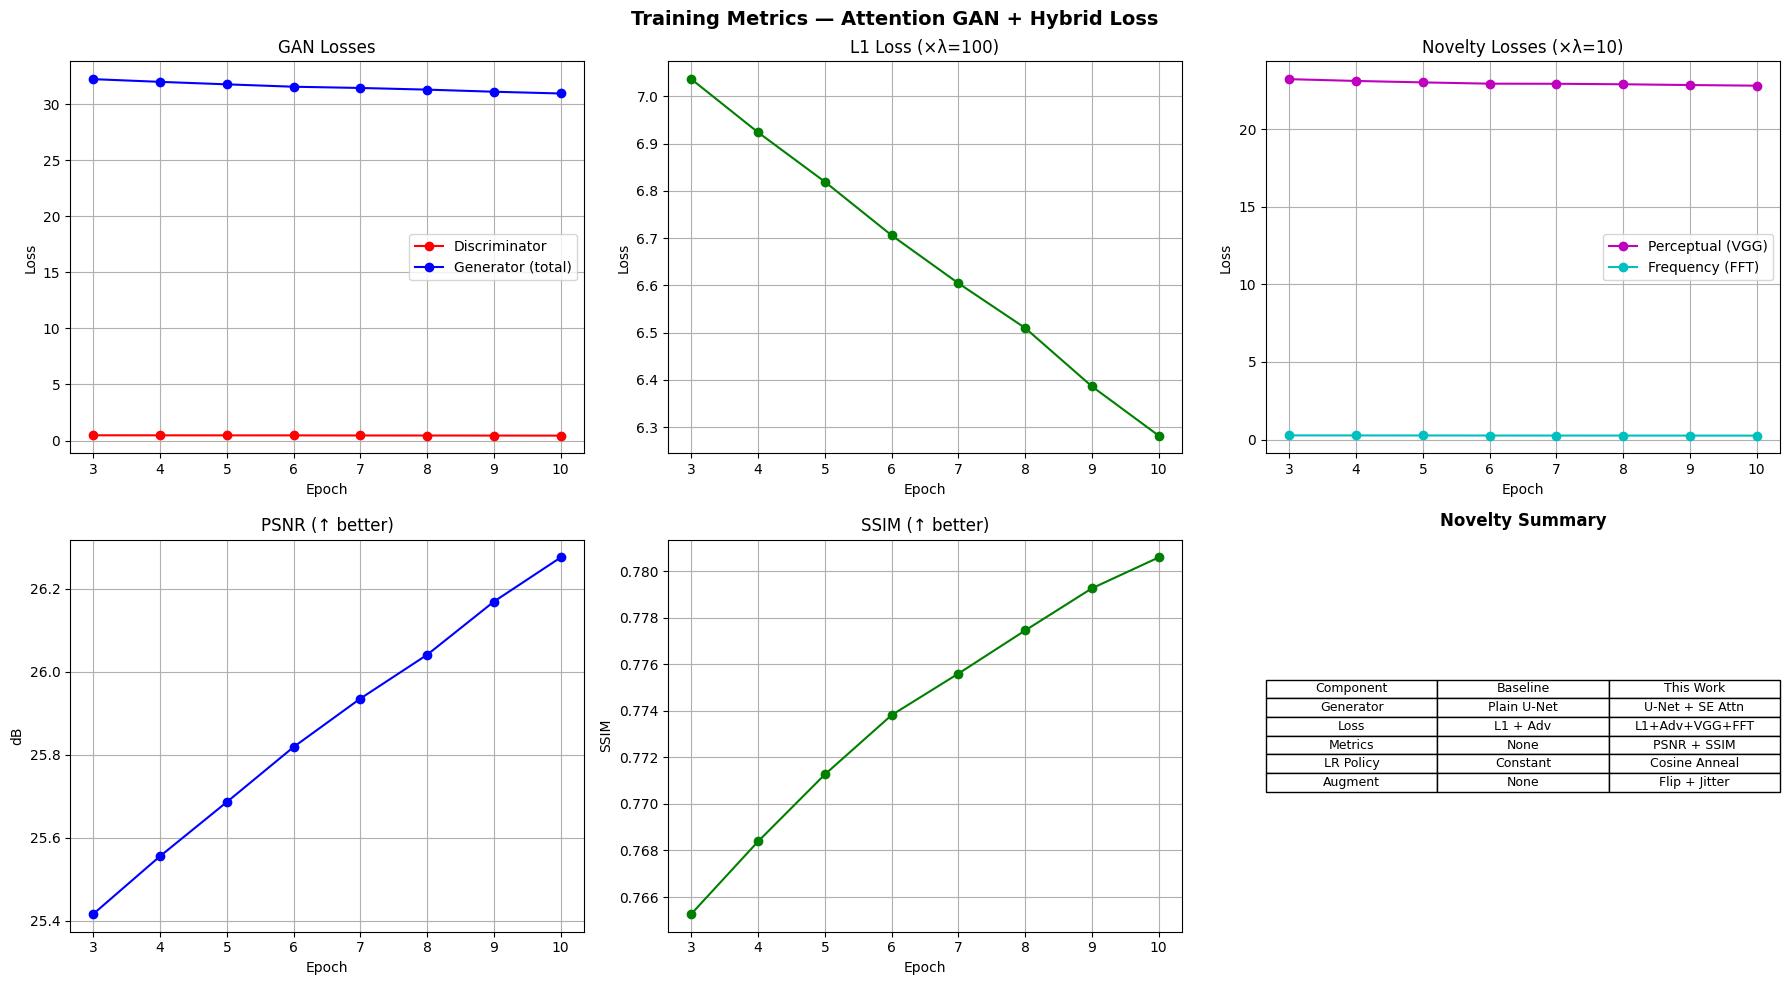

In [69]:
epochs = history['epoch']
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Training Metrics — Attention GAN + Hybrid Loss', fontsize=14, fontweight='bold')


axes[0, 0].plot(epochs, history['loss_D'], 'r-o', label='Discriminator')
axes[0, 0].plot(epochs, history['loss_G'], 'b-o', label='Generator (total)')
axes[0, 0].set(title='GAN Losses', xlabel='Epoch', ylabel='Loss')
axes[0, 0].legend(); axes[0, 0].grid(True)

axes[0, 1].plot(epochs, history['loss_L1'], 'g-o')
axes[0, 1].set(title='L1 Loss (×λ=100)', xlabel='Epoch', ylabel='Loss')
axes[0, 1].grid(True)

axes[0, 2].plot(epochs, history['loss_percep'], 'm-o', label='Perceptual (VGG)')
axes[0, 2].plot(epochs, history['loss_freq'],   'c-o', label='Frequency (FFT)')
axes[0, 2].set(title='Novelty Losses (×λ=10)', xlabel='Epoch', ylabel='Loss')
axes[0, 2].legend(); axes[0, 2].grid(True)


axes[1, 0].plot(epochs, history['train_psnr'], 'b-o')
axes[1, 0].set(title='PSNR (↑ better)', xlabel='Epoch', ylabel='dB')
axes[1, 0].grid(True)

axes[1, 1].plot(epochs, history['train_ssim'], 'g-o')
axes[1, 1].set(title='SSIM (↑ better)', xlabel='Epoch', ylabel='SSIM')
axes[1, 1].grid(True)


axes[1, 2].axis('off')
summary_data = [
    ['Component', 'Baseline', 'This Work'],
    ['Generator', 'Plain U-Net', 'U-Net + SE Attn'],
    ['Loss', 'L1 + Adv', 'L1+Adv+VGG+FFT'],
    ['Metrics', 'None', 'PSNR + SSIM'],
    ['LR Policy', 'Constant', 'Cosine Anneal'],
    ['Augment', 'None', 'Flip + Jitter'],
]
tbl = axes[1, 2].table(cellText=summary_data[1:],
                        colLabels=summary_data[0],
                        loc='center', cellLoc='center')
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
axes[1, 2].set_title('Novelty Summary', fontweight='bold', pad=10)

plt.tight_layout()
plt.savefig('training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

In [70]:
BEST_EPOCH = NUM_EPOCHS  

generator.load_state_dict(
    torch.load(f"generator_epoch_{BEST_EPOCH}.pth", map_location=DEVICE)
)
generator.eval()

psnr_metric.reset()
ssim_metric.reset()

psnr_blur_metric = PeakSignalNoiseRatio(data_range=1.0).to(DEVICE)
ssim_blur_metric = StructuralSimilarityIndexMeasure(data_range=1.0).to(DEVICE)

with torch.no_grad():
    for blur_imgs, sharp_imgs in tqdm(test_loader, desc="Evaluating"):
        blur_imgs  = blur_imgs.to(DEVICE)
        sharp_imgs = sharp_imgs.to(DEVICE)
        fake_imgs  = generator(blur_imgs)

        pred_01  = to_01(fake_imgs)
        sharp_01 = to_01(sharp_imgs)
        blur_01  = to_01(blur_imgs)

        psnr_metric.update(pred_01,  sharp_01)
        ssim_metric.update(pred_01,  sharp_01)
        psnr_blur_metric.update(blur_01, sharp_01)
        ssim_blur_metric.update(blur_01, sharp_01)

test_psnr      = psnr_metric.compute().item()
test_ssim      = ssim_metric.compute().item()
baseline_psnr  = psnr_blur_metric.compute().item()
baseline_ssim  = ssim_blur_metric.compute().item()

print("\n" + "="*50)
print("TEST SET QUANTITATIVE RESULTS")
print("="*50)
print(f"{'Metric':<20} {'Blurred Input':>14} {'Model Output':>14} {'Δ':>8}")
print("-"*58)
print(f"{'PSNR (dB)':<20} {baseline_psnr:>14.2f} {test_psnr:>14.2f}"
      f" {test_psnr - baseline_psnr:>+8.2f}")
print(f"{'SSIM':<20} {baseline_ssim:>14.4f} {test_ssim:>14.4f}"
      f" {test_ssim - baseline_ssim:>+8.4f}")
print("="*50)

Evaluating: 100%|██████████| 82/82 [00:18<00:00,  4.38it/s]


TEST SET QUANTITATIVE RESULTS
Metric                Blurred Input   Model Output        Δ
----------------------------------------------------------
PSNR (dB)                     19.53          26.33    +6.80
SSIM                         0.6036         0.7905  +0.1869


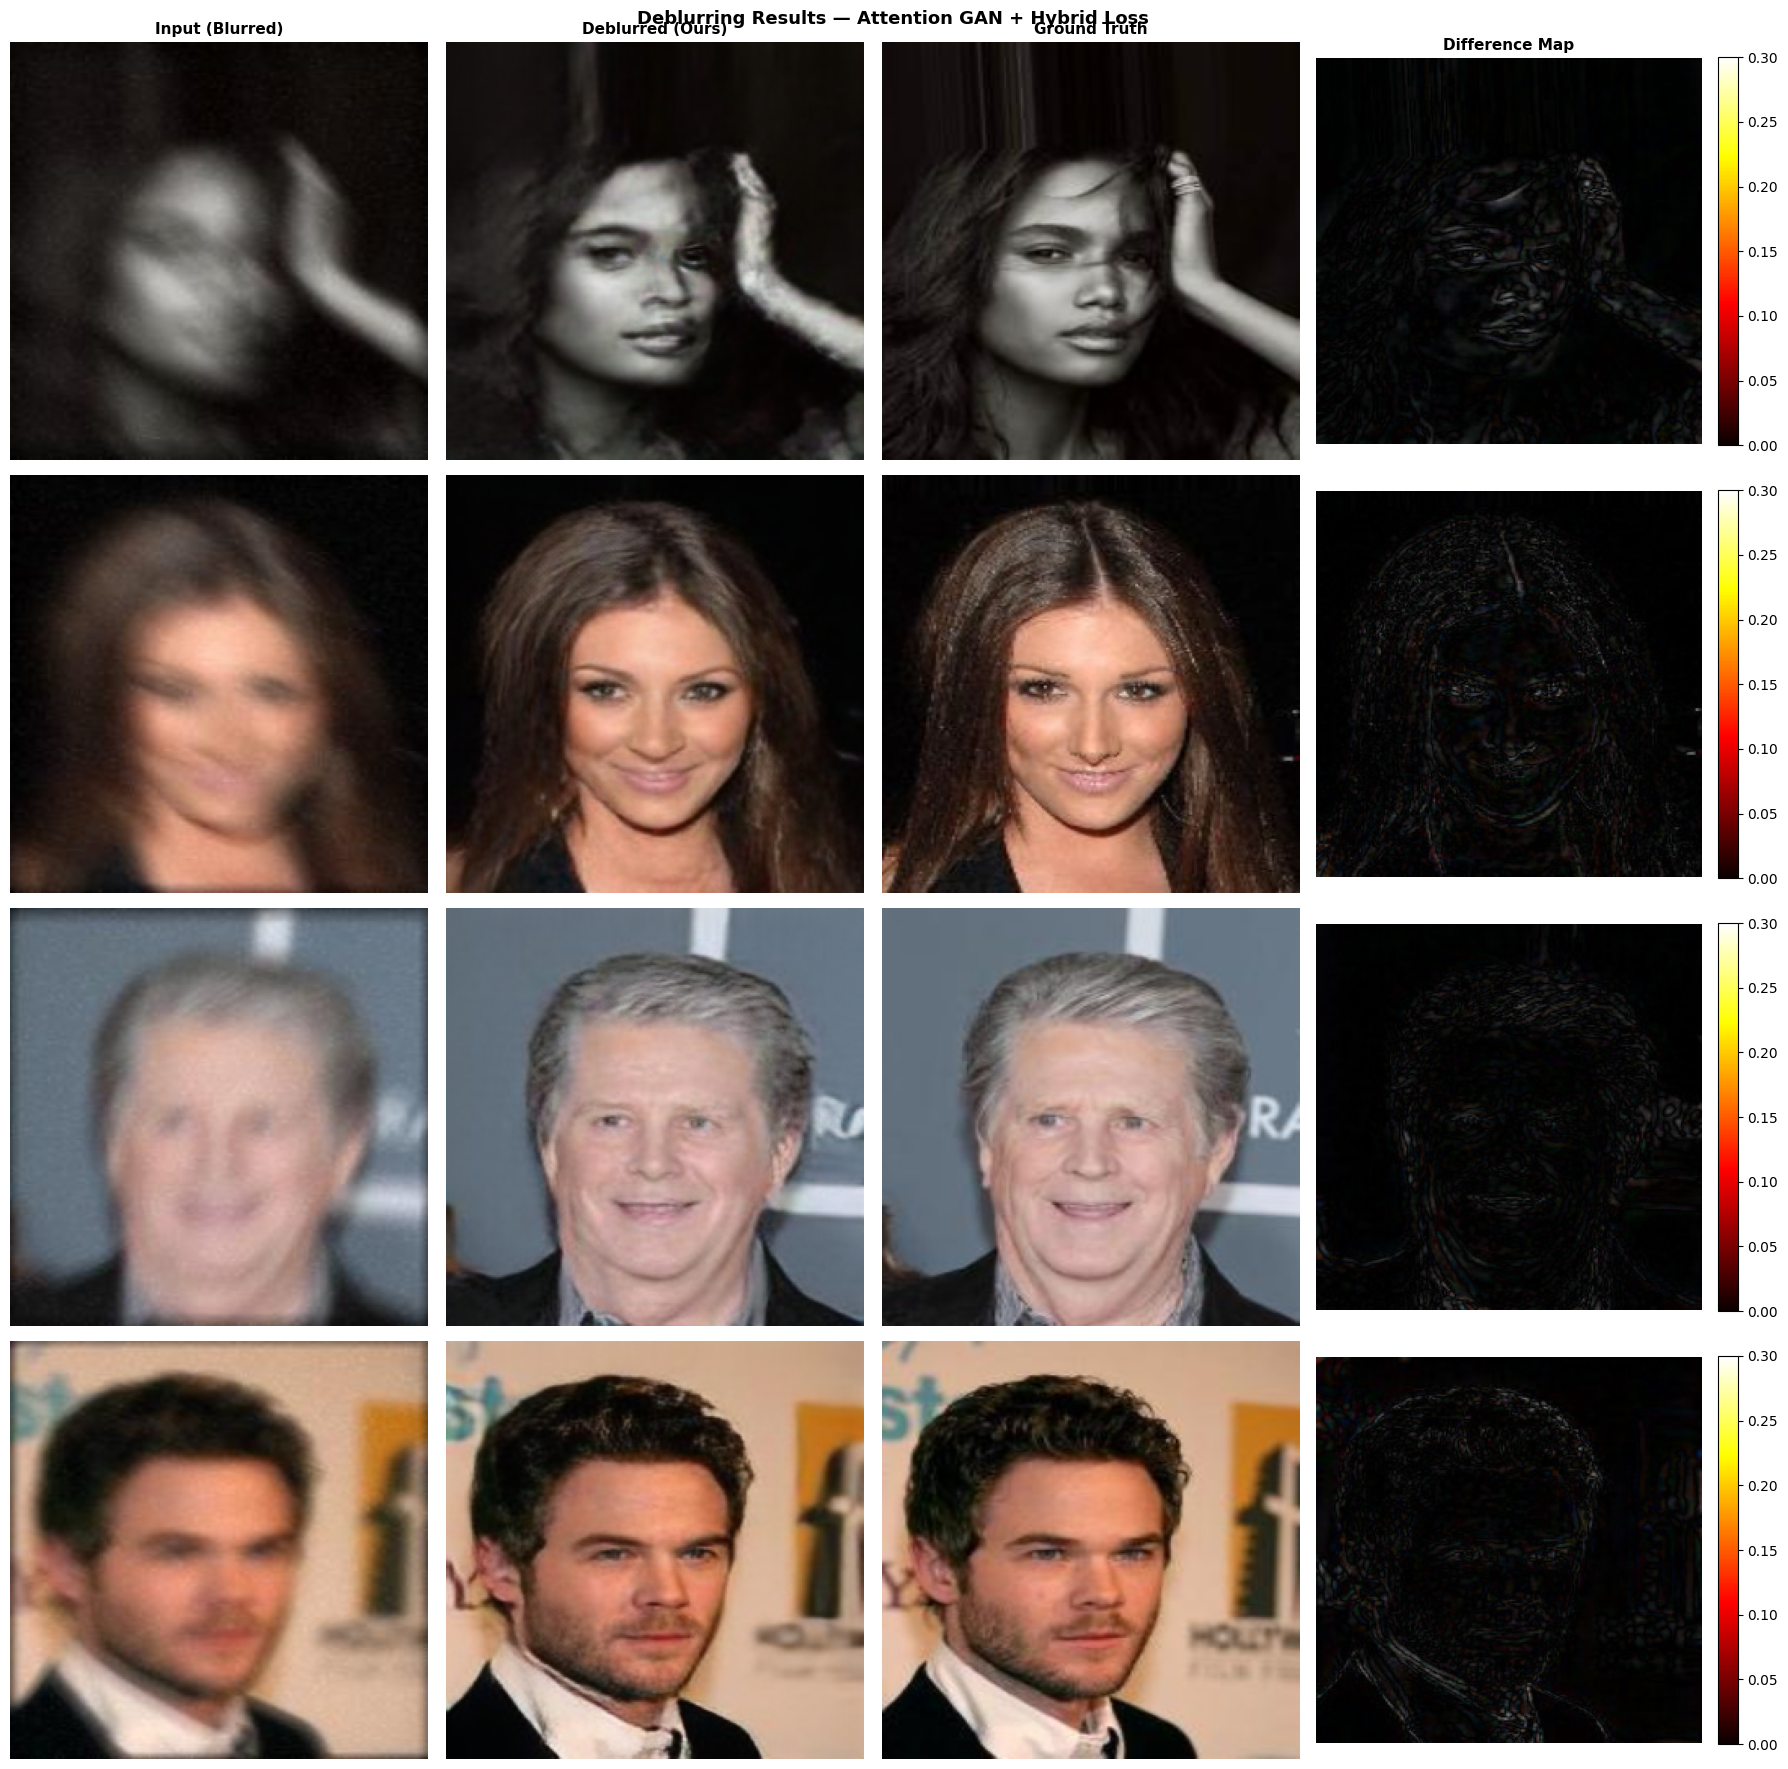

In [71]:
test_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5]*3, std=[0.5]*3)
])


def unnorm(t: torch.Tensor) -> np.ndarray:

    return (t.squeeze().permute(1, 2, 0).cpu().numpy() * 0.5 + 0.5).clip(0, 1)


def visualize_results(n: int = 4):
    files = sorted(os.listdir(Test_Blur_Dir))
    samples = random.sample(files, n)

    fig, axes = plt.subplots(n, 4, figsize=(18, 4.5 * n))
    fig.suptitle('Deblurring Results — Attention GAN + Hybrid Loss',
                 fontsize=13, fontweight='bold')

    col_titles = ['Input (Blurred)', 'Deblurred (Ours)', 'Ground Truth', 'Difference Map']
    for ax, title in zip(axes[0], col_titles):
        ax.set_title(title, fontsize=11, fontweight='bold')

    generator.eval()
    with torch.no_grad():
        for row, fname in enumerate(samples):
            blur_img  = Image.open(os.path.join(Test_Blur_Dir,  fname)).convert('RGB')
            sharp_img = Image.open(os.path.join(Test_Sharp_Dir, fname)).convert('RGB')

            inp    = test_transform(blur_img).unsqueeze(0).to(DEVICE)
            pred   = generator(inp)

            blur_np  = unnorm(test_transform(blur_img))
            pred_np  = unnorm(pred)
            sharp_np = unnorm(test_transform(sharp_img))
            diff_np  = np.abs(pred_np - sharp_np)

            img_psnr = psnr_metric(
                to_01(pred),
                to_01(test_transform(sharp_img).unsqueeze(0).to(DEVICE))
            ).item()

            axes[row, 0].imshow(blur_np);  axes[row, 0].axis('off')
            axes[row, 1].imshow(pred_np);  axes[row, 1].axis('off')
            axes[row, 1].set_xlabel(f'PSNR: {img_psnr:.2f} dB', fontsize=9)
            axes[row, 2].imshow(sharp_np); axes[row, 2].axis('off')
            im = axes[row, 3].imshow(diff_np, cmap='hot', vmin=0, vmax=0.3)
            axes[row, 3].axis('off')
            plt.colorbar(im, ax=axes[row, 3], fraction=0.046, pad=0.04)

    plt.tight_layout()
    plt.savefig('visual_results.png', dpi=150, bbox_inches='tight')
    plt.show()


visualize_results(n=4)

In [73]:

ablation_data = {
    'Configuration': [
        'Baseline (L1 + Adv only)',
        '+ SE Attention',
        '+ Perceptual Loss',
        '+ Frequency Loss',
        'Full Model (Ours)',
    ],
    'PSNR (dB)': [None, None, None, None, None],  
    'SSIM':      [None, None, None, None, None],
}

df_ablation = pd.DataFrame(ablation_data)
print(df_ablation.to_string(index=False))

           Configuration PSNR (dB) SSIM
Baseline (L1 + Adv only)      None None
          + SE Attention      None None
       + Perceptual Loss      None None
        + Frequency Loss      None None
       Full Model (Ours)      None None
